# SHA Flight-Service Patterns Around China's 2026 National Day Holiday

**Research questions:**
1. How did flight-service volume and cancellation rates vary before, during, and after the holiday?
2. Were cancellations and departures delayed by at least 60 minutes concentrated on particular dates or departure hours?
3. How did the October 10 adjusted workday compare with ordinary weekend dates in the observed flight-event records?

This notebook uses the supplied `sha_master.csv`. China's 2026 National Day calendar identifies September 20 and October 10 as adjusted workdays. The dataset covers September 22–October 22, so only October 10 is observed; September 20 is outside the data window, not a zero-flight observation. For this analysis, scheduled and actual departure timestamps are assumed accurate, and a difference of at least 60 minutes is treated as a departure delay.

**Scope and data boundary:** The unit of observation is a flight-event record. These data do not establish passenger demand, complete scheduled-flight coverage, or causal calendar effects.

In [1]:
from pathlib import Path
from datetime import date, timedelta, datetime

import pandas as pd
from IPython.display import Image, display

DATA = Path('sha_master.csv')
if not DATA.exists():
    DATA = Path('..') / 'sha_master.csv'
FIG = Path('final_project_word/figures')
if not FIG.is_dir():
    FIG = Path('figures')
if not FIG.is_dir():
    raise FileNotFoundError('Report figures are missing; run scripts/build_word_final_project.py first.')
df = pd.read_csv(DATA, encoding='utf-8-sig', keep_default_na=False)
df['_date'] = pd.to_datetime(df['local_date']).dt.date
df['_hour'] = df['local_hour'].astype(int)
print(f'{len(df):,} records; {df["local_date"].nunique()} dates')
print(f'Unique event IDs: {df["event_id"].nunique()}')

23,705 records; 31 dates
Unique event IDs: 23705


## Methods and definitions

- **Flight status:** the source-reported flight-progress or outcome label in `status_display` (for example, `Canceled`, `Landed [time]`, `Estimated departure [time]`, or `Diverted to [airport]`).
- **Known status:** a flight-status label that is neither blank nor `unknown`.
- **Cancellation rate:** cancelled known-status records ÷ all known-status records, expressed as a percentage (a per-record share, not a time-based rate).
- **Period comparison:** RQ1 compares three consecutive 7-day windows; daily results supplement the period-level comparison.
- **Departure delay:** `actual_departure_utc - scheduled_departure_utc >= 60` minutes among known-status, non-cancelled departures with both timestamps. This analysis assumes the scheduled and actual timestamps are valid and represent the named events.
- **Hour bands:** morning 06–11, afternoon 12–16, evening 17–22, and night/other 23–05.
- **Adjusted-workday scope:** September 20 and October 10 are calendar make-up workdays, but September 20 is outside the observed date range.
- The source's `timing_semantics_verified` flag is false, but this analysis treats the timestamps as valid under the stated assumption.

In [2]:
def known(status):
    normalized = status.str.strip().str.lower()
    return normalized.ne('') & normalized.ne('unknown')

def cancelled(status):
    return status.str.strip().str.lower().eq('canceled')

def pct(n,d):
    return 100*n/d if d else 0

def summarize(frame):
    known_status = known(frame['status_display'])
    k = int(known_status.sum())
    c = int((cancelled(frame['status_display']) & known_status).sum())
    return {'events':len(frame), 'known':k, 'unknown':len(frame)-k, 'cancelled':c,
            'cancellation_pct':pct(c,k)}

## RQ1 — Comparison across equal-length calendar phases

To answer how outcomes varied before, during, and after the holiday, this section first compares three consecutive seven-day windows: 24–30 September (pre-holiday), 1–7 October (National Day), and 8–14 October (post-holiday). Each window must contain all seven dates. The pre-holiday window includes the 25–27 September Mid-Autumn public holidays, while the post-holiday window includes the 10 October adjusted workday, so these are chronological—not calendar-identical—phases.

The period summaries give the before/during/after comparison. The daily chart below supplements them because period averages can conceal high- or low-cancellation dates within a window. This figure is the same report-generated `daily_trends.png` used in the Word report.

RQ1 period comparison (three complete seven-day windows):
      Period                    Dates  Events Events/day  Known status  Unknown status  Cancellations Cancellation rate
 Pre-holiday 2026-09-24 to 2026-09-30    5351      764.4          5348               3            200             3.74%
National Day 2026-10-01 to 2026-10-07    5381      768.7          5380               1            103             1.91%
Post-holiday 2026-10-08 to 2026-10-14    5126      732.3          5097              29            123             2.41%


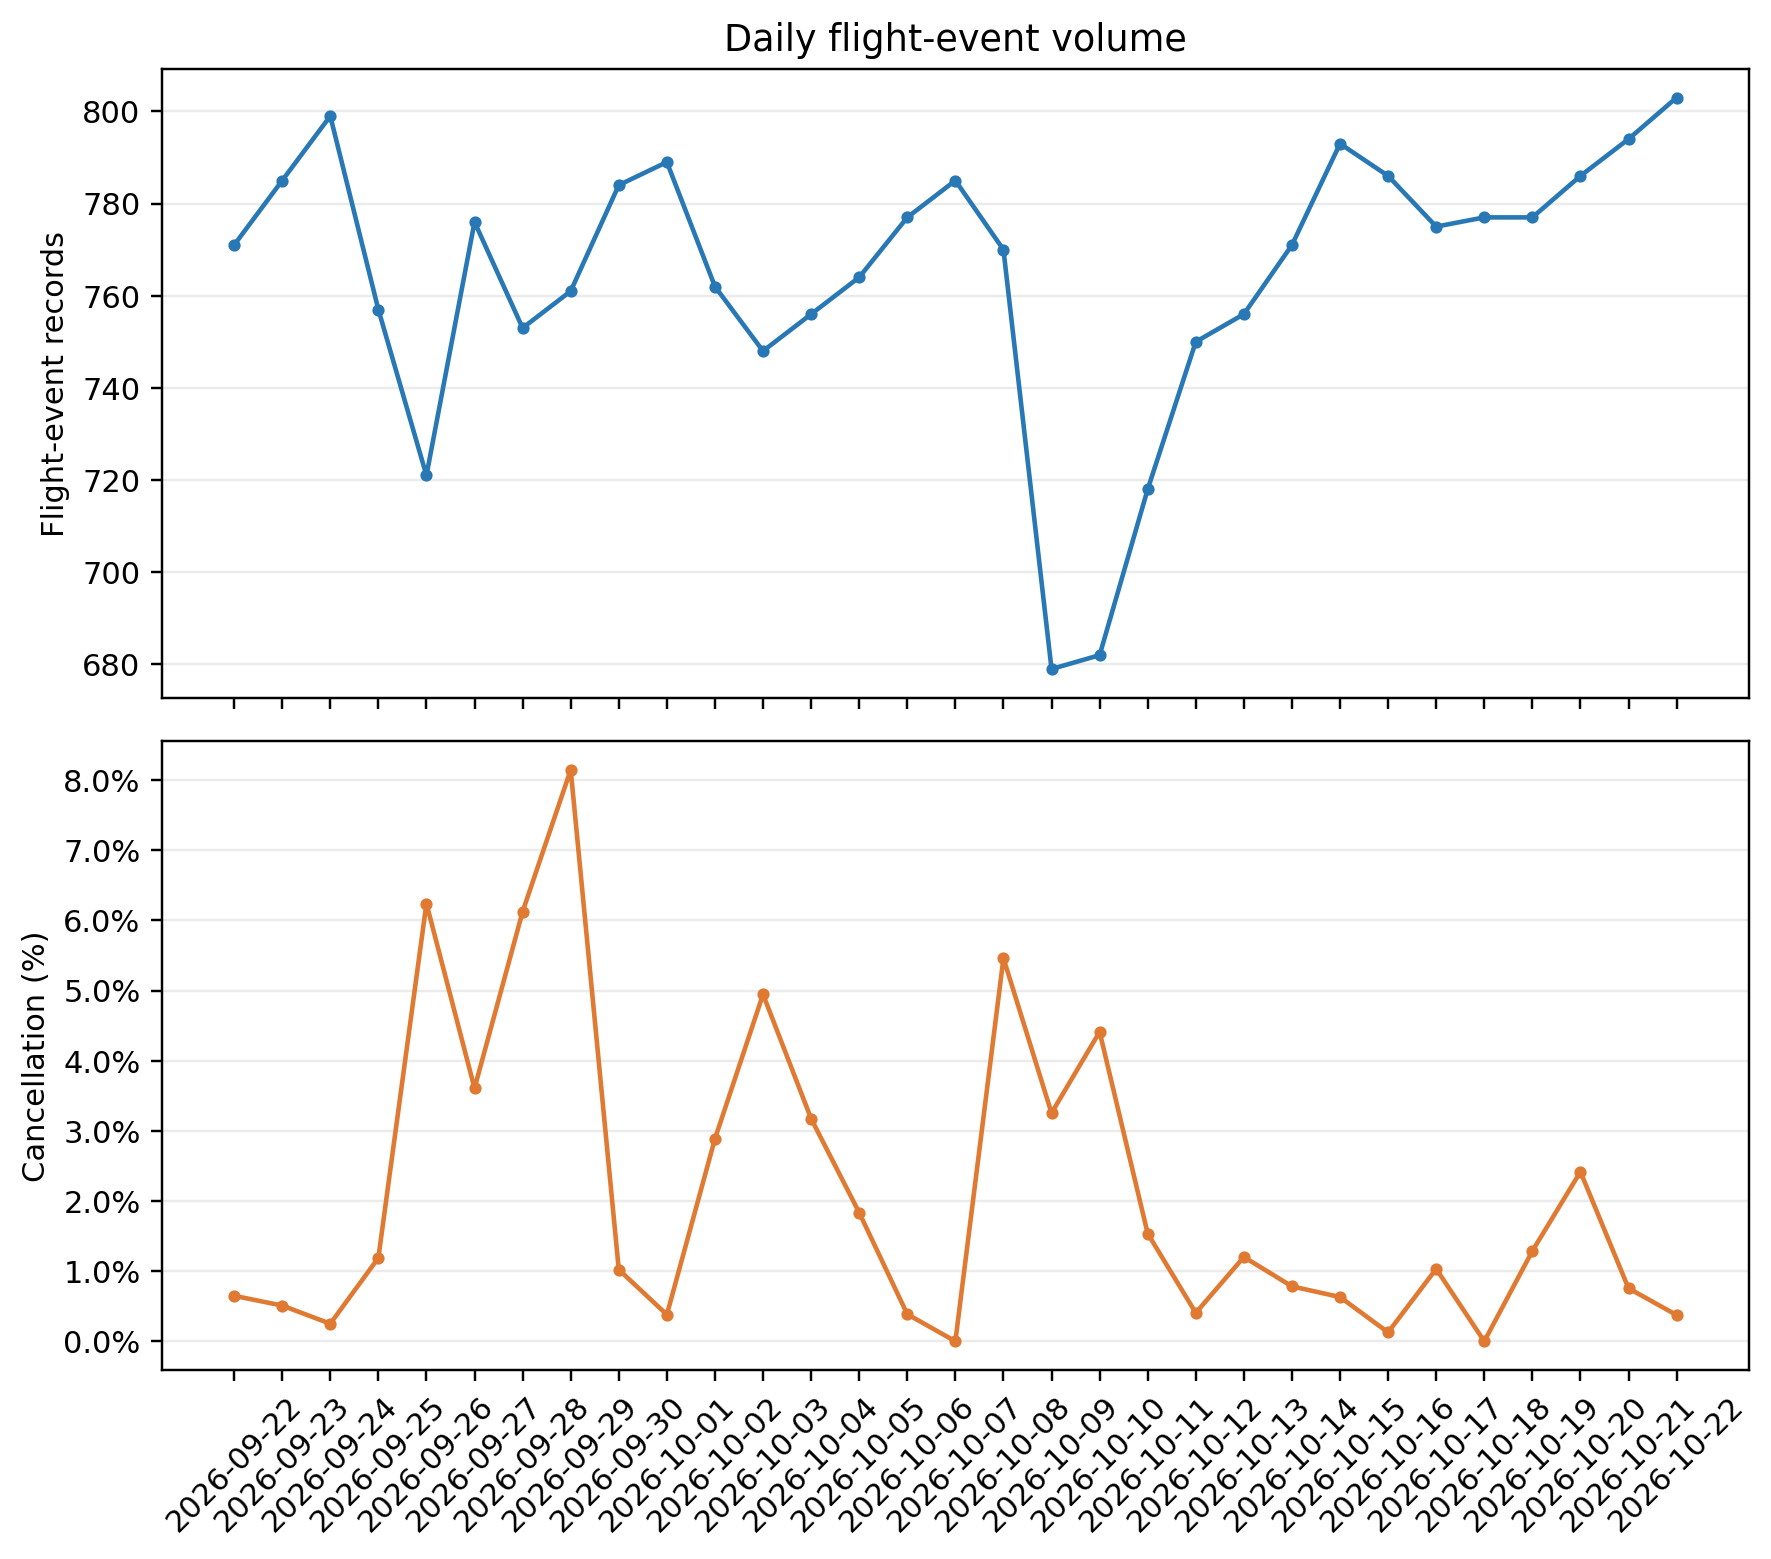

Calendar qualifiers: 25–27 Sep = Mid-Autumn public holiday; 1–7 Oct = National Day holiday; 10 Oct = adjusted workday.


In [3]:
holiday = date(2026,10,1)
periods = [('Pre-holiday', holiday-timedelta(days=7), holiday-timedelta(days=1)),
           ('National Day', holiday, holiday+timedelta(days=6)),
           ('Post-holiday', holiday+timedelta(days=7), holiday+timedelta(days=13))]
period_rows = []
for label,start,end in periods:
    subset=df.loc[df['_date'].between(start, end)]
    if subset['_date'].nunique() != 7:
        raise ValueError(f'{label} period must contain all 7 dates: {start} to {end}')
    summary=summarize(subset)
    period_rows.append({
        'Period': label,
        'Dates': f'{start} to {end}',
        'Events': summary['events'],
        'Events/day': len(subset)/7,
        'Known status': summary['known'],
        'Unknown status': summary['unknown'],
        'Cancellations': summary['cancelled'],
        'Cancellation rate': summary['cancellation_pct'],
    })
period_summary = pd.DataFrame(period_rows)
print('RQ1 period comparison (three complete seven-day windows):')
print(period_summary.to_string(index=False, formatters={
    'Events/day': '{:.1f}'.format,
    'Cancellation rate': '{:.2f}%'.format,
}))

by_date = {d: group for d, group in df.groupby('_date', sort=True)}
daily = [(d, summarize(group)) for d, group in by_date.items()]
display(Image(filename=str(FIG / 'daily_trends.png')))
print('Calendar qualifiers: 25–27 Sep = Mid-Autumn public holiday; 1–7 Oct = National Day holiday; 10 Oct = adjusted workday.')

## RQ2 — Concentration on dates and hours

The numerator is a date/hour count of departures with a delay of at least 60 minutes. It is compared with the eligible known-status, non-cancelled departure denominator. Cancellations are analysed separately and are not eligible for departure-delay calculation.

Eligible departures: 11560 missing timestamps: 10 delays ≥60 min: 514
Highest date-level delay proportions: [(datetime.date(2026, 10, 19), 380, 99, 26.05263157894737), (datetime.date(2026, 9, 26), 335, 75, 22.388059701492537), (datetime.date(2026, 10, 2), 367, 35, 9.536784741144414), (datetime.date(2026, 9, 24), 399, 34, 8.521303258145364), (datetime.date(2026, 10, 18), 386, 28, 7.253886010362694)]
Afternoon (12–16) eligible departures= 3529 delays ≥60 min= 170 delay percentage= 4.82
Evening (17–22) eligible departures= 3406 delays ≥60 min= 233 delay percentage= 6.84
Morning (06–11) eligible departures= 4531 delays ≥60 min= 110 delay percentage= 2.43
Night/other eligible departures= 94 delays ≥60 min= 1 delay percentage= 1.06


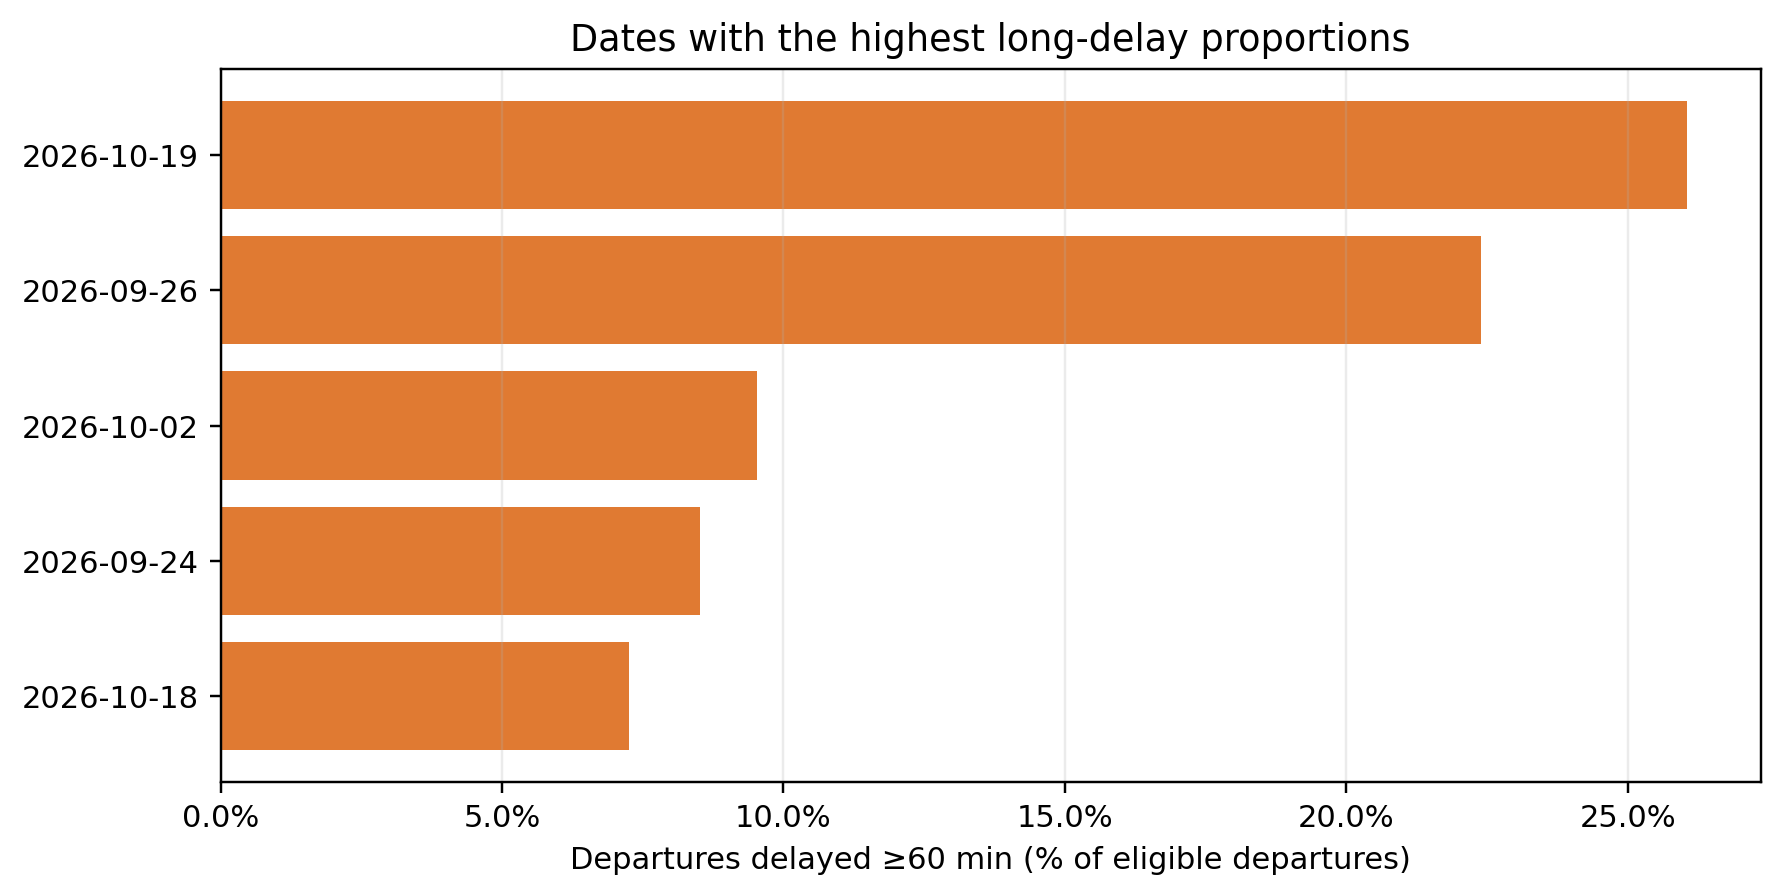

In [4]:
departure_mask = (
    df['direction'].eq('departure')
    & known(df['status_display'])
    & ~cancelled(df['status_display'])
)
departures = df.loc[departure_mask]
has_timestamps = (
    departures['scheduled_departure_utc'].ne('')
    & departures['actual_departure_utc'].ne('')
)
missing = int((~has_timestamps).sum())
eligible = departures.loc[has_timestamps].copy()
eligible['gap'] = (
    pd.to_datetime(eligible['actual_departure_utc'], utc=True)
    - pd.to_datetime(eligible['scheduled_departure_utc'], utc=True)
).dt.total_seconds() / 60

date_ext = []
for d, group in eligible.groupby('_date', sort=True):
    extreme = int(group['gap'].ge(60).sum())
    date_ext.append((d, len(group), extreme, pct(extreme, len(group))))
print('Eligible departures:',len(eligible),'missing timestamps:',missing,
      'delays ≥60 min:',int(eligible['gap'].ge(60).sum()))
print('Highest date-level delay proportions:',sorted(date_ext,key=lambda x:(-x[3],-x[2]))[:5])

def hour_band(hour):
    if 6 <= hour <= 11:
        return 'Morning (06–11)'
    if 12 <= hour <= 16:
        return 'Afternoon (12–16)'
    if 17 <= hour <= 22:
        return 'Evening (17–22)'
    return 'Night/other'

eligible['_band'] = eligible['_hour'].map(hour_band)
for band, group in eligible.groupby('_band', sort=True):
    extreme = int(group['gap'].ge(60).sum())
    print(band, 'eligible departures=',len(group),'delays ≥60 min=',extreme,
          'delay percentage=',round(pct(extreme,len(group)),2))

display(Image(filename=str(FIG / 'extreme_dates.png')))

The date-level view is not a test of recurring causation. October 10 is examined separately because ordinary weekday/weekend labels are not sufficient descriptions in China's adjusted-workday calendar. The long-delay date chart is the same report-generated `extreme_dates.png` used in the Word report.

In [5]:
print('Top cancellation dates')
top=sorted(daily,key=lambda ds:(-ds[1]['cancellation_pct'],ds[0].isoformat()))[:5]
for d,s in top:
    print(d.isoformat(), s)

print('October 10 adjusted workday')
print(summarize(df.loc[df['_date'].eq(date(2026,10,10))]))
print('Ordinary weekends')
for d,s in daily:
    if by_date[d]['calendar_day_type'].iloc[0]=='weekend':
        print(d.isoformat(),s)

Top cancellation dates
2026-09-29 {'events': 761, 'known': 761, 'unknown': 0, 'cancelled': 62, 'cancellation_pct': 8.147174770039422}
2026-09-26 {'events': 721, 'known': 721, 'unknown': 0, 'cancelled': 45, 'cancellation_pct': 6.2413314840499305}
2026-09-28 {'events': 753, 'known': 751, 'unknown': 2, 'cancelled': 46, 'cancellation_pct': 6.125166444740346}
2026-10-08 {'events': 770, 'known': 769, 'unknown': 1, 'cancelled': 42, 'cancellation_pct': 5.461638491547464}
2026-10-03 {'events': 748, 'known': 748, 'unknown': 0, 'cancelled': 37, 'cancellation_pct': 4.946524064171123}
October 10 adjusted workday
{'events': 682, 'known': 680, 'unknown': 2, 'cancelled': 30, 'cancellation_pct': 4.411764705882353}
Ordinary weekends
2026-10-11 {'events': 718, 'known': 716, 'unknown': 2, 'cancelled': 11, 'cancellation_pct': 1.5363128491620113}
2026-10-17 {'events': 775, 'known': 775, 'unknown': 0, 'cancelled': 8, 'cancellation_pct': 1.032258064516129}
2026-10-18 {'events': 777, 'known': 777, 'unknown': 0

## RQ3 — Adjusted workday case study

October 10 was officially a Saturday adjusted workday. The closest ordinary-Saturday comparison in the data is October 17. October 11 and 18 provide Sunday context; public-holiday weekend dates remain separately labelled. September 20, the other National Day make-up workday, is outside the dataset. These one-date comparisons are descriptive and cannot establish a recurring adjusted-workday effect. Hour-band counts describe recorded events, not verified scheduled capacity or passenger demand.

Calendar make-up workdays: 2026-09-20 and 2026-10-10
Observed date range: 2026-09-22 to 2026-10-22
September 20 is outside the dataset and is not a zero-flight observation.

Weekend and adjusted-workday outcomes:
      date  weekday calendar_day_type public_holiday  events  arrivals  departures  known  unknown  cancelled cancellation_pct  eligible_gap_departures  gap60_count gap60_pct  Morning (06–11)  Afternoon (12–16)  Evening (17–22)  Night/other
2026-09-26 Saturday    public_holiday     mid_autumn     721       361         360    721        0         45            6.24%                      335           75    22.39%              218                232              240           31
2026-09-27   Sunday    public_holiday     mid_autumn     776       387         389    776        0         28            3.61%                      375           23     6.13%              222                237              283           34
2026-10-03 Saturday    public_holiday   national_day     748    

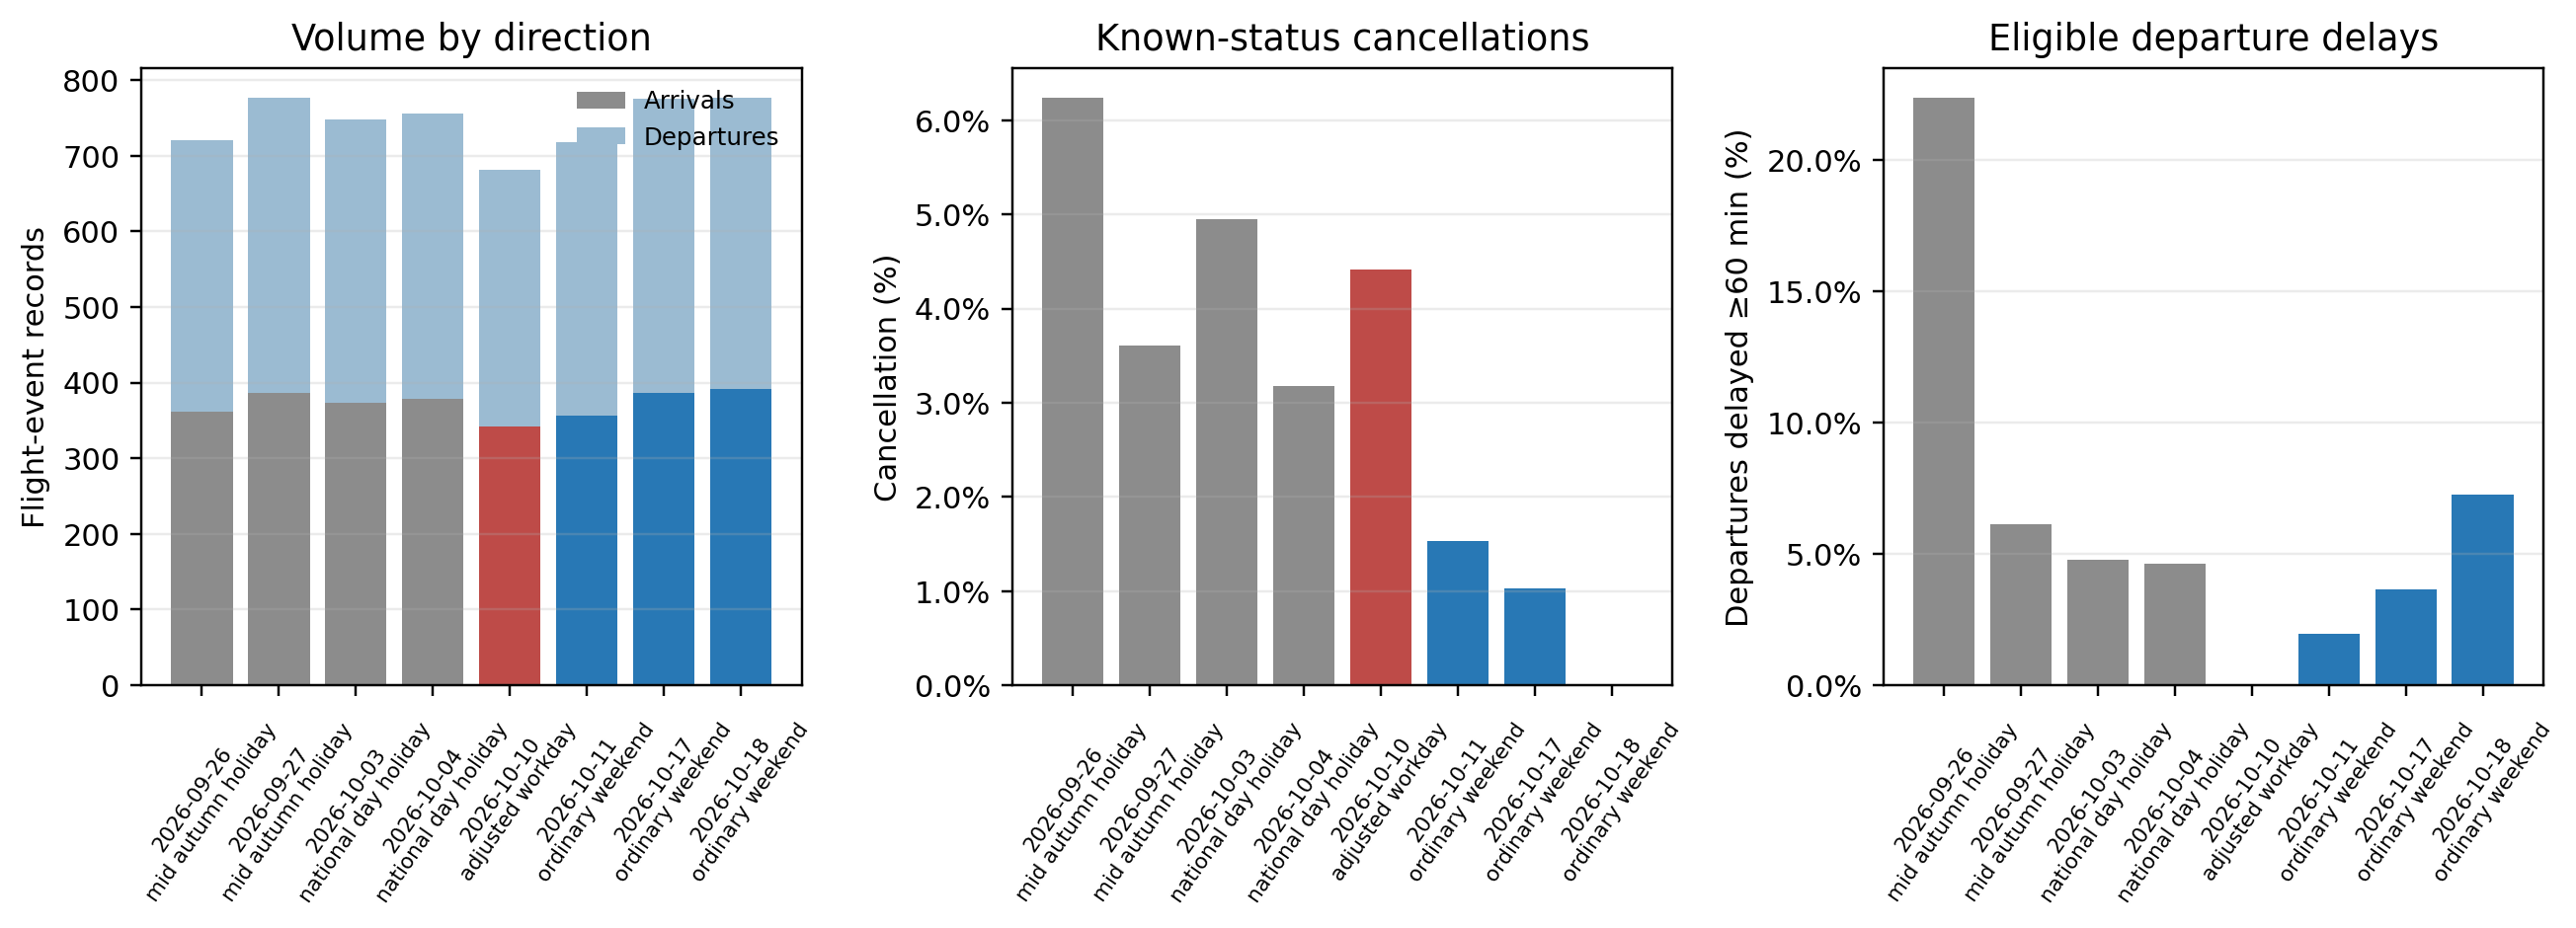


Recorded event counts by local-hour band: October 10 vs October 17
      date  Morning (06–11)  Afternoon (12–16)  Evening (17–22)  Night/other
2026-10-10              198                216              239           29
2026-10-17              227                242              270           36


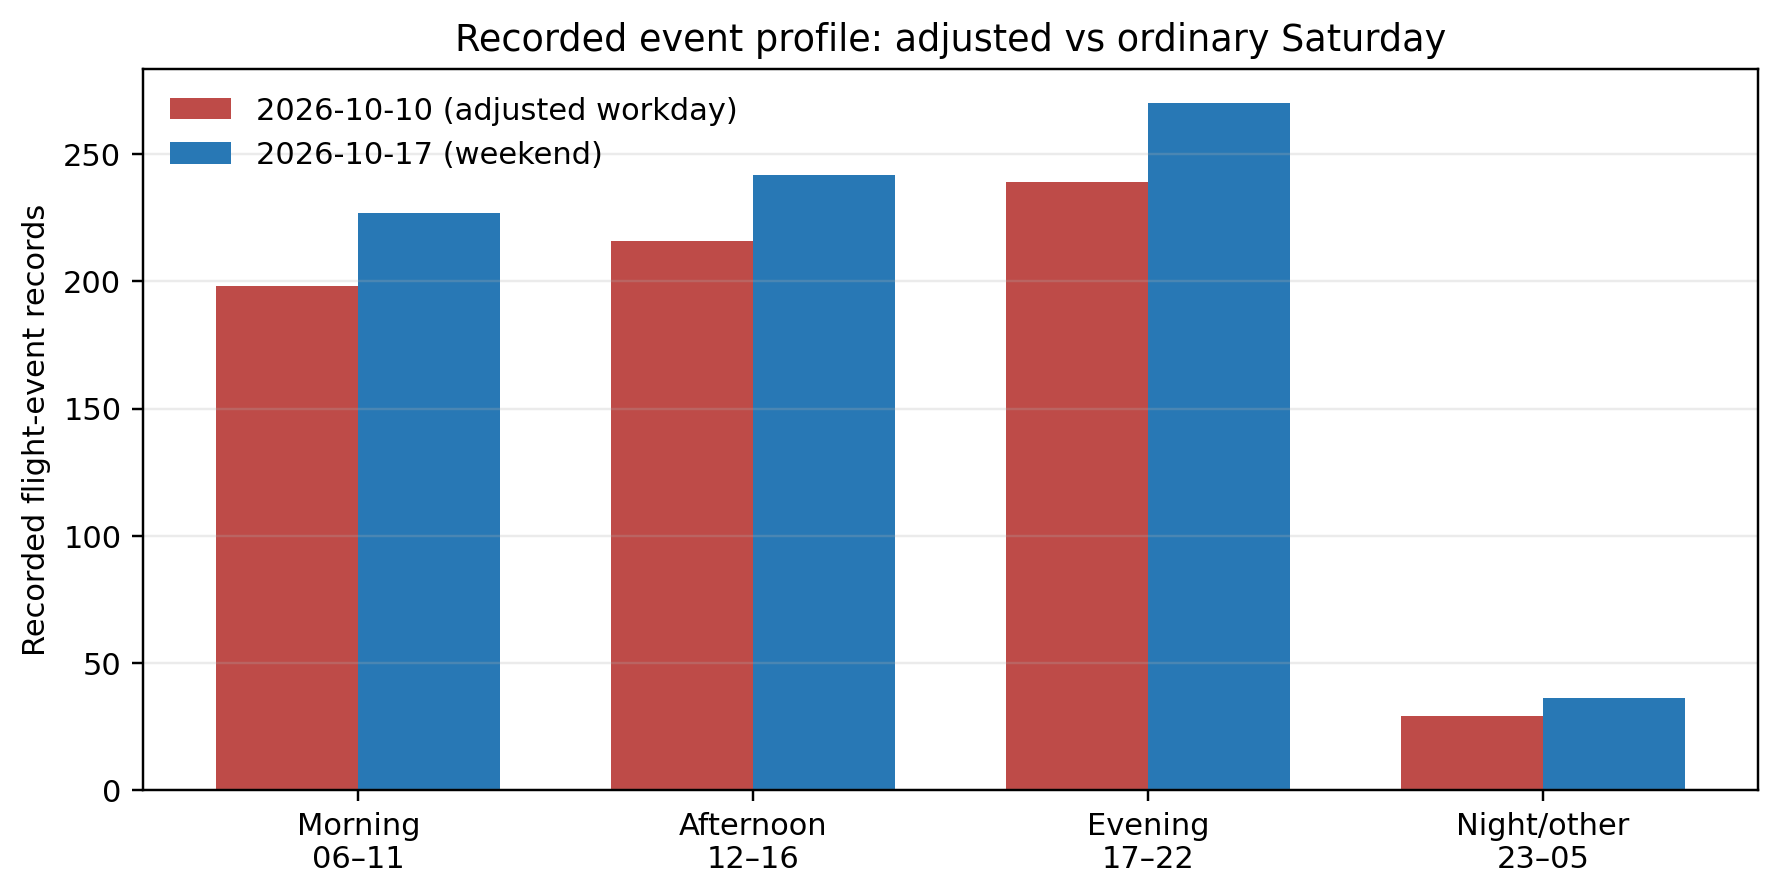

In [6]:
adjusted_flag = df['adjusted_workday'].astype(str).str.lower().eq('true')
focus = df.loc[df['weekday'].isin(['Saturday', 'Sunday']) | adjusted_flag]
comparison_rows = []
for d, group in focus.groupby('_date', sort=True):
    summary = summarize(group)
    day_eligible = eligible.loc[eligible['_date'].eq(d)]
    extreme = int(day_eligible['gap'].ge(60).sum())
    band_counts = (
        group.assign(_band=group['_hour'].map(hour_band))
        .groupby('_band').size()
    )
    comparison_rows.append({
        'date': d.isoformat(),
        'weekday': group['weekday'].iloc[0],
        'calendar_day_type': group['calendar_day_type'].iloc[0],
        'public_holiday': group['public_holiday'].iloc[0],
        'events': summary['events'],
        'arrivals': int(group['direction'].eq('arrival').sum()),
        'departures': int(group['direction'].eq('departure').sum()),
        'known': summary['known'],
        'unknown': summary['unknown'],
        'cancelled': summary['cancelled'],
        'cancellation_pct': summary['cancellation_pct'],
        'eligible_gap_departures': len(day_eligible),
        'gap60_count': extreme,
        'gap60_pct': pct(extreme, len(day_eligible)),
        **{band: int(band_counts.get(band, 0)) for band in (
            'Morning (06–11)', 'Afternoon (12–16)', 'Evening (17–22)', 'Night/other'
        )},
    })
comparison = pd.DataFrame(comparison_rows)
print('Calendar make-up workdays: 2026-09-20 and 2026-10-10')
print('Observed date range:', df['local_date'].min(), 'to', df['local_date'].max())
print('September 20 is outside the dataset and is not a zero-flight observation.')
print('\nWeekend and adjusted-workday outcomes:')
print(comparison.to_string(index=False, formatters={
    'cancellation_pct': '{:.2f}%'.format,
    'gap60_pct': '{:.2f}%'.format,
}))

display(Image(filename=str(FIG / 'adjusted_workday.png')))

matched_saturday = comparison.loc[comparison['date'].isin(['2026-10-10', '2026-10-17'])]
hour_columns = ['Morning (06–11)', 'Afternoon (12–16)', 'Evening (17–22)', 'Night/other']
print('\nRecorded event counts by local-hour band: October 10 vs October 17')
print(matched_saturday[['date', *hour_columns]].to_string(index=False))
display(Image(filename=str(FIG / 'adjusted_workday_hours.png')))

## Conclusions

The observed October 10 adjusted workday had fewer recorded events and a higher cancellation rate than October 17, the closest ordinary-Saturday comparison. Under the timestamp assumption used in this analysis, its eligible departure subset had no delays ≥60 minutes, compared with 14 of 384 on October 17. This contrast is descriptive only: the dates differ in schedule and operating conditions, and event coverage is not a verified measure of scheduled capacity. Only one of the two calendar make-up workdays falls within the dataset. The findings cannot establish an adjusted-workday effect. A stronger investigation requires data for September 20, multiple comparable workdays and years, complete schedule coverage, and relevant operational and demand data.